<Axes: xlabel='Rank', ylabel='Number of reads per cell'>

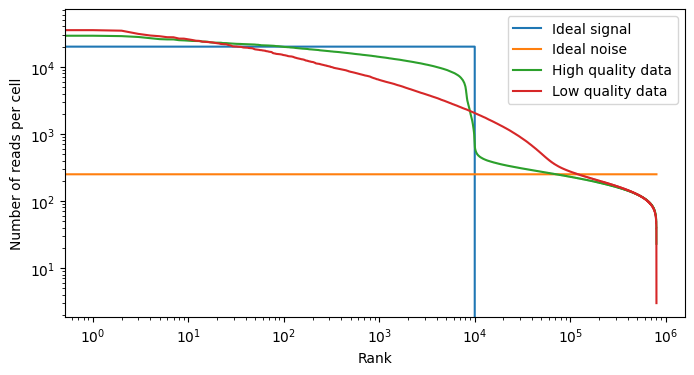

In [100]:
import numpy as np
import pandas as pd

n_whitelist = 800_000
n_reads = 200_000_000
n_truecells = 10_000
n_intermediate = 2_000
n_highquality = n_truecells - n_intermediate
median_counts = 10_000

good_true_cell_counts = np.round(
    np.random.lognormal(mean=np.log(median_counts), sigma=0.3, size=n_highquality)
)

good_intermediate_counts = np.round(
    np.random.lognormal(mean=np.log(median_counts / 5), sigma=0.5, size=n_intermediate)
)

remaining_reads = n_reads - int(good_true_cell_counts.sum()) - int(good_intermediate_counts.sum())
background_mean = remaining_reads / (n_whitelist - n_truecells)
good_background_counts = np.round(
    np.random.lognormal(mean=np.log(background_mean), sigma=0.4, size=n_whitelist - n_truecells)
)

bad_true_cell_counts = np.round(
    np.random.lognormal(mean=np.log(median_counts / 20), sigma=1.1, size=n_truecells * 10)
)

remaining_reads = n_reads - int(bad_true_cell_counts.sum())
background_mean = remaining_reads / (n_whitelist - n_truecells)
bad_background_counts = np.round(
    np.random.lognormal(
        mean=np.log(background_mean),
        sigma=0.4,
        size=n_whitelist - len(bad_true_cell_counts),
    )
)

df = pd.DataFrame(
    {
        "rank": range(n_whitelist),
        "good_data": np.sort(
            np.concatenate([good_true_cell_counts, good_intermediate_counts, good_background_counts])
        )[::-1],
        "ideal_noise": [round(n_reads / n_whitelist)] * n_whitelist,
        "ideal_signal": [round(n_reads / n_truecells)] * n_truecells
        + [0] * (n_whitelist - n_truecells),
        "bad_data": np.sort(np.concatenate([bad_true_cell_counts, bad_background_counts]))[::-1],
    }
)

df.plot(
    x="rank",
    y=["ideal_signal", "ideal_noise", "good_data", "bad_data"],
    logx=True,
    logy=True,
    label=["Ideal signal", "Ideal noise", "High quality data", "Low quality data"],
    xlabel="Rank",
    ylabel="Number of reads per cell",
    figsize=(8, 4),
)
